In [30]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [31]:
# Read the uploaded CSV file
df = pd.read_csv('/content/customer_clustering_dataset.csv')

# Display the first five rows
print(df.head())

# Check the number of rows and columns
print(df.shape)

# Check for missing values
print(df.isnull().sum().sum())

# Check for duplicate rows
print(df.duplicated().sum())

  Customer_ID  Annual_Income_k  Spending_Score  Purchase_Frequency_Monthly  \
0   CUST00001            20.17           21.32                          10   
1   CUST00002            18.00           25.56                           9   
2   CUST00003            18.00           32.33                           9   
3   CUST00004            24.74           27.22                           8   
4   CUST00005            18.00           25.54                          11   

   Average_Order_Value  Website_Visits_Monthly  Discount_Sensitivity  \
0              1777.96                      15                 56.73   
1               970.67                      20                 71.28   
2              1019.37                      21                 63.18   
3              1096.94                      21                 67.44   
4              1378.44                      20                 70.35   

   Days_Since_Last_Purchase  
0                        35  
1                        44  
2       

In [32]:
# Remove Customer_ID because it is only an identifier
X = df.drop('Customer_ID', axis=1)

# Display the selected features
print(X.head())

   Annual_Income_k  Spending_Score  Purchase_Frequency_Monthly  \
0            20.17           21.32                          10   
1            18.00           25.56                           9   
2            18.00           32.33                           9   
3            24.74           27.22                           8   
4            18.00           25.54                          11   

   Average_Order_Value  Website_Visits_Monthly  Discount_Sensitivity  \
0              1777.96                      15                 56.73   
1               970.67                      20                 71.28   
2              1019.37                      21                 63.18   
3              1096.94                      21                 67.44   
4              1378.44                      20                 70.35   

   Days_Since_Last_Purchase  
0                        35  
1                        44  
2                        42  
3                        47  
4                   

In [33]:
# Create the scaler
scaler = StandardScaler()

# Standardize all numerical features
X_scaled = scaler.fit_transform(X)

print("Data standardized successfully")

Data standardized successfully


In [34]:
# Create the Hierarchical Clustering model
hc = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

# Fit the model and assign cluster labels
df['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

# Display the cluster assigned to each customer
print(df[['Customer_ID', 'Hierarchical_Cluster']].head(10))

  Customer_ID  Hierarchical_Cluster
0   CUST00001                     3
1   CUST00002                     3
2   CUST00003                     3
3   CUST00004                     3
4   CUST00005                     3
5   CUST00006                     3
6   CUST00007                     3
7   CUST00008                     3
8   CUST00009                     3
9   CUST00010                     3


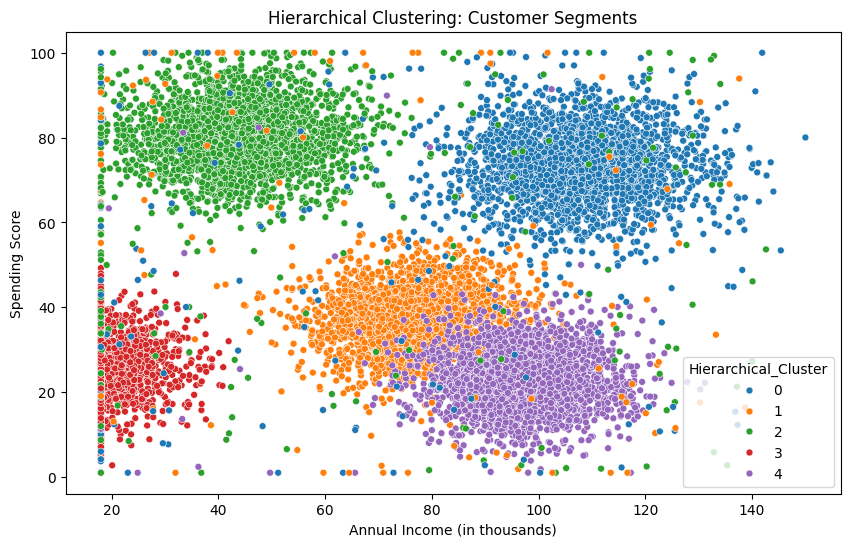

In [35]:
# Plot customer clusters using income and spending score
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual_Income_k'],
    y=df['Spending_Score'],
    hue=df['Hierarchical_Cluster'],
    palette='tab10',
    s=25
)

plt.title('Hierarchical Clustering: Customer Segments')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.show()

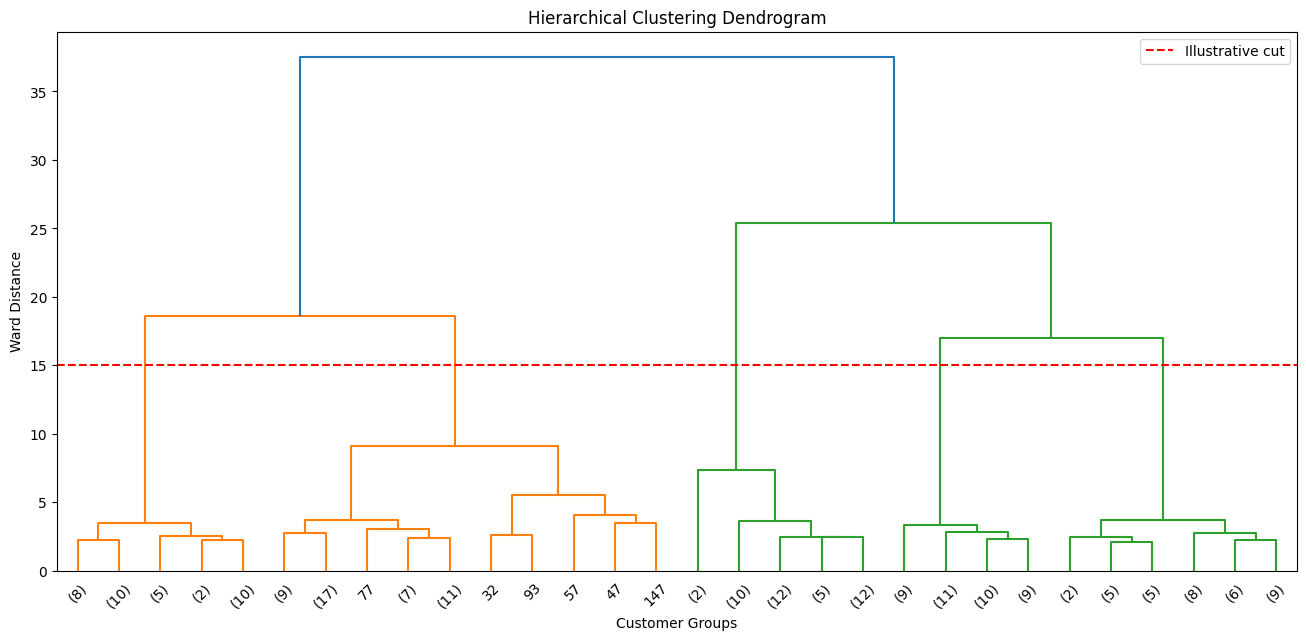

In [36]:
from scipy.cluster.hierarchy import dendrogram, linkage
# Select 200 customers for a readable dendrogram
sample = df.sample(n=200, random_state=42)

# Select and standardize their numerical features
X_sample = sample.drop('Customer_ID', axis=1)
X_sample_scaled = StandardScaler().fit_transform(X_sample)

# Perform hierarchical clustering using Ward linkage
linked = linkage(X_sample_scaled, method='ward')

# Plot the dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Groups')
plt.ylabel('Ward Distance')
plt.axhline(y=15, color='red', linestyle='--', label='Illustrative cut')
plt.legend()
plt.show()

In [37]:
#Evaluate Clusters
# Calculate the Silhouette Score
score = silhouette_score(X_scaled, df['Hierarchical_Cluster'])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.543


In [38]:
#DBSCAN
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [39]:
# Create the DBSCAN model
dbscan = DBSCAN(
    eps=0.7,
    min_samples=10
)

# Fit the model and assign cluster labels
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Display the assigned clusters
print(df[['Customer_ID', 'DBSCAN_Cluster']].head(10))

  Customer_ID  DBSCAN_Cluster
0   CUST00001               0
1   CUST00002               0
2   CUST00003               0
3   CUST00004               0
4   CUST00005               0
5   CUST00006               0
6   CUST00007               0
7   CUST00008               0
8   CUST00009               0
9   CUST00010               0


In [40]:
# Count observations in each cluster
print(df['DBSCAN_Cluster'].value_counts().sort_index())

# Count observations identified as noise
noise_count = (df['DBSCAN_Cluster'] == -1).sum()

print("Number of noise points:", noise_count)

# Count the actual clusters, excluding noise
number_of_clusters = len(set(df['DBSCAN_Cluster'])) - (
    1 if -1 in df['DBSCAN_Cluster'] else 0
)

print("Number of clusters:", number_of_clusters)

DBSCAN_Cluster
-1     548
 0    2303
 1    2288
 2    2297
 3    2267
 4    2297
Name: count, dtype: int64
Number of noise points: 548
Number of clusters: 6


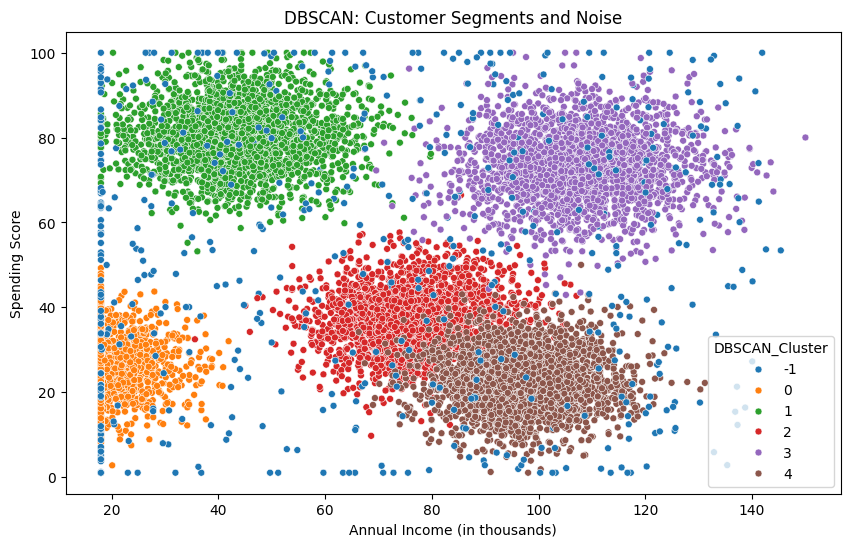

In [41]:
# Visualize clusters using income and spending score
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual_Income_k'],
    y=df['Spending_Score'],
    hue=df['DBSCAN_Cluster'],
    palette='tab10',
    s=25
)

plt.title('DBSCAN: Customer Segments and Noise')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.show()

In [42]:
#Evaluation DBSCAN
# Identify observations that are not noise
mask = df['DBSCAN_Cluster'] != -1

# Get the cluster labels excluding noise
labels = df.loc[mask, 'DBSCAN_Cluster']

# Calculate the score only if there are at least two clusters
if labels.nunique() >= 2 and labels.nunique() < len(labels):

    score = silhouette_score(
        X_scaled[mask],
        labels
    )

    print("Silhouette Score:", round(score, 3))

else:
    print("Silhouette Score cannot be calculated meaningfully.")
    print("Try adjusting eps or min_samples.")

Silhouette Score: 0.591


In [43]:
  #Experiment with DBSCAN parameters
#If DBSCAN identifies only one cluster or labels most observations as noise, try changing eps.
# Try different eps values
for eps_value in [0.5, 0.7, 0.9, 1.1, 1.3]:

    # Create and fit a new DBSCAN model
    model = DBSCAN(
        eps=eps_value,
        min_samples=10
    )

    labels = model.fit_predict(X_scaled)

    # Count clusters, excluding noise
    clusters = len(set(labels)) - (1 if -1 in labels else 0)

    # Count noise points
    noise = (labels == -1).sum()

    print(
        "eps:", eps_value,
        "| Clusters:", clusters,
        "| Noise points:", noise
    )

eps: 0.5 | Clusters: 5 | Noise points: 1748
eps: 0.7 | Clusters: 5 | Noise points: 548
eps: 0.9 | Clusters: 3 | Noise points: 465
eps: 1.1 | Clusters: 3 | Noise points: 430
eps: 1.3 | Clusters: 1 | Noise points: 381


In [44]:
#Again running DBSCAN with least noise eps
# Create the DBSCAN model
dbscan = DBSCAN(
    eps=0.9,
    min_samples=10
)

# Fit the model and assign cluster labels
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Display the assigned clusters
print(df[['Customer_ID', 'DBSCAN_Cluster']].head(10))

  Customer_ID  DBSCAN_Cluster
0   CUST00001               0
1   CUST00002               0
2   CUST00003               0
3   CUST00004               0
4   CUST00005               0
5   CUST00006               0
6   CUST00007               0
7   CUST00008               0
8   CUST00009               0
9   CUST00010               0


In [45]:
#KMEANS
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

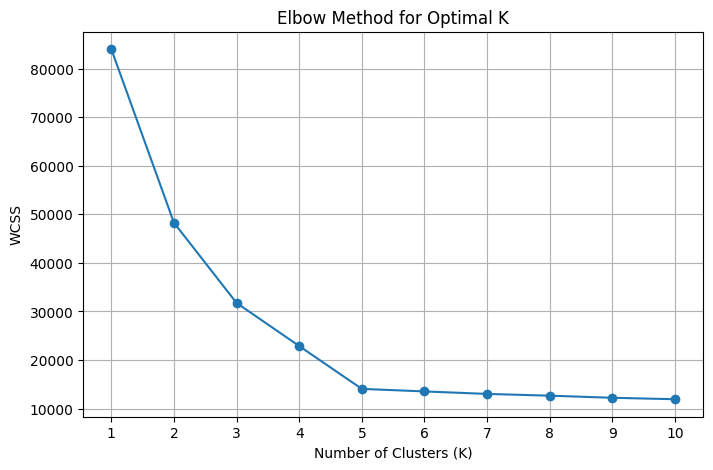

In [46]:
#elbow
# Store the WCSS values for different K values
wcss = []

# Test cluster counts from 1 to 10
for k in range(1, 11):

    # Create the K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model
    kmeans.fit(X_scaled)

    # Store the WCSS value
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [47]:
# Create the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Display customer IDs and their assigned clusters
print(df[['Customer_ID', 'KMeans_Cluster']].head(10))

  Customer_ID  KMeans_Cluster
0   CUST00001               3
1   CUST00002               3
2   CUST00003               3
3   CUST00004               3
4   CUST00005               3
5   CUST00006               3
6   CUST00007               3
7   CUST00008               3
8   CUST00009               3
9   CUST00010               3


In [48]:
# Count the number of customers in each cluster
print(df['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    2417
1    2425
2    2395
3    2387
4    2376
Name: count, dtype: int64


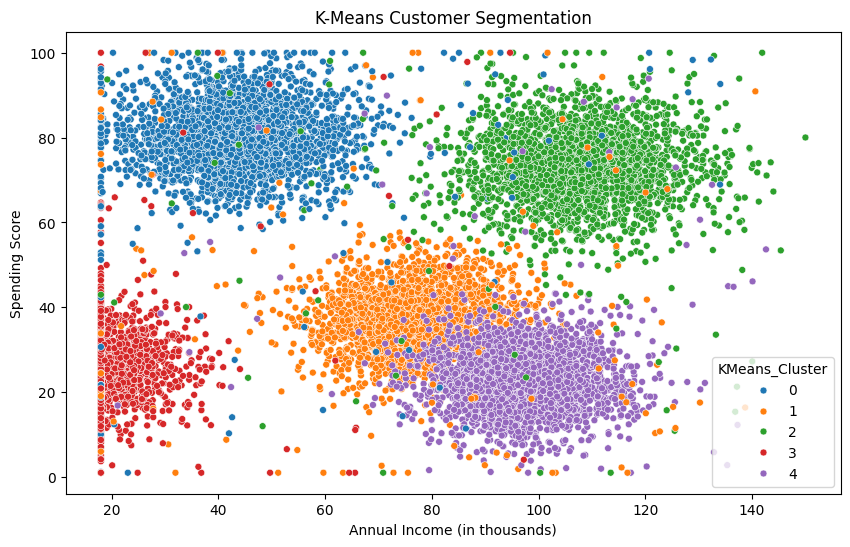

In [49]:
# Create a scatter plot of the customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='KMeans_Cluster',
    palette='tab10',
    s=25
)

plt.title('K-Means Customer Segmentation')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.show()

In [50]:
# Calculate the Silhouette Score
score = silhouette_score(
    X_scaled,
    df['KMeans_Cluster']
)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.552


In [58]:
#TUNING MODELS-
#K-Means: Hyperparameter tuning
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score, make_scorer

# Create a custom Silhouette Score scorer
def silhouette_scorer(estimator, X):
    labels = estimator.fit_predict(X)

    if len(set(labels)) < 2:
        return -1

    return silhouette_score(X, labels)

# Create the model
kmeans = KMeans(random_state=42, n_init=10)

# Define parameters to test
params = {
    'n_clusters': [2, 3, 4, 5, 6, 7, 8, 9, 10]
}

# Run parameter search
grid = GridSearchCV(
    kmeans,
    params,
    scoring=silhouette_scorer,
    cv=3,
    n_jobs=-1
)

grid.fit(X_scaled)

# Display the best parameters and score
print("Best Parameters:", grid.best_params_)
print("Best Silhouette Score:", grid.best_score_)

# Save the best model
best_kmeans = grid.best_estimator_

# Assign final clusters
df['KMeans_Cluster_Tuned'] = best_kmeans.fit_predict(X_scaled)

Best Parameters: {'n_clusters': 2}
Best Silhouette Score: 0.6211547294272822


In [59]:
#Hierarchical Clustering: Hyperparameter tuning
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import silhouette_score

# Test different parameter combinations
params = {
    'n_clusters': [2, 3, 4, 5, 6, 7, 8],
    'linkage': ['ward', 'complete', 'average']
}

best_score = -1
best_params = None
best_hc = None

# Test each combination on the standardized data
for p in ParameterGrid(params):

    # Ward linkage requires Euclidean distance
    model = AgglomerativeClustering(**p)

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    if score > best_score:
        best_score = score
        best_params = p
        best_hc = model

# Display the best parameters and score
print("Best Parameters:", best_params)
print("Best Silhouette Score:", best_score)

# Assign final clusters using the best parameters
best_hc = AgglomerativeClustering(**best_params)
df['HC_Cluster_Tuned'] = best_hc.fit_predict(X_scaled)

Best Parameters: {'linkage': 'ward', 'n_clusters': 8}
Best Silhouette Score: 0.5515129202948098


In [60]:
#DBSCAN: Hyperparameter tuning
#DBSCAN cannot use ordinary GridSearchCV because clustering labels are not directly comparable across folds in cross validation.
#We can instead test parameter combinations and select the best valid Silhouette Score.
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid
import numpy as np

# Define parameter combinations to test
params = {
    'eps': [0.5, 0.7, 0.9, 1.1, 1.3, 1.5],
    'min_samples': [5, 10, 15, 20]
}

best_score = -1
best_params = None

# Use a sample for faster tuning
X_tune = X_scaled[:2000]

# Test each combination
for p in ParameterGrid(params):

    model = DBSCAN(**p)
    labels = model.fit_predict(X_tune)

    # Exclude noise points
    mask = labels != -1
    valid_labels = labels[mask]
    valid_data = X_tune[mask]

    # Calculate score only when at least two clusters exist
    if (
        len(valid_labels) > 1
        and len(np.unique(valid_labels)) >= 2
        and len(np.unique(valid_labels)) < len(valid_labels)
    ):
        score = silhouette_score(valid_data, valid_labels)

        if score > best_score:
            best_score = score
            best_params = p

# Display the best parameters
print("Best Parameters:", best_params)
print("Best Silhouette Score:", best_score)

# Fit the best DBSCAN model on the full dataset
if best_params is not None:
    best_dbscan = DBSCAN(**best_params)
    df['DBSCAN_Cluster_Tuned'] = best_dbscan.fit_predict(X_scaled)

    print("Noise points:", (df['DBSCAN_Cluster_Tuned'] == -1).sum())
else:
    print("No valid configuration found. Try increasing eps.")

Best Parameters: None
Best Silhouette Score: -1
No valid configuration found. Try increasing eps.


In [61]:
#Find the best DBSCAN parameters
# Store DBSCAN results
dbscan_results = []

# Test different parameter values
eps_values = [1.5, 2.0, 2.5, 3.0, 3.5]
min_samples_values = [5, 10, 20]

for eps in eps_values:

    for min_samples in min_samples_values:

        # Create the DBSCAN model
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        # Fit DBSCAN on the full dataset
        labels = model.fit_predict(X_scaled)

        # Count clusters, excluding noise label -1
        clusters = len(set(labels)) - (1 if -1 in labels else 0)

        # Calculate percentage of noise observations
        noise_percentage = (labels == -1).mean() * 100

        # Calculate Silhouette Score on non-noise observations
        valid_indices = np.where(labels != -1)[0]

        # Sample up to 2000 non-noise observations
        if len(valid_indices) > 2000:
            valid_indices = rng.choice(
                valid_indices, size=2000, replace=False
            )

        valid_labels = labels[valid_indices]

        # Score only when at least two clusters are represented
        if (
            len(valid_indices) > 1
            and len(np.unique(valid_labels)) >= 2
            and len(np.unique(valid_labels)) < len(valid_labels)
        ):
            score = silhouette_score(
                X_scaled[valid_indices],
                valid_labels
            )
        else:
            score = np.nan

        dbscan_results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Clusters': clusters,
            'Noise %': round(noise_percentage, 2),
            'Silhouette Score': score
        })

# Display the results
dbscan_results = pd.DataFrame(dbscan_results)

print(
    dbscan_results.sort_values(
        'Silhouette Score',
        ascending=False,
        na_position='last'
    ).round(3)
)

    eps  min_samples  Clusters  Noise %  Silhouette Score
0   1.5            5         3     2.39             0.165
1   1.5           10         1     2.75               NaN
2   1.5           20         1     2.79               NaN
3   2.0            5         1     0.28               NaN
4   2.0           10         1     0.74               NaN
5   2.0           20         1     0.95               NaN
6   2.5            5         1     0.01               NaN
7   2.5           10         1     0.01               NaN
8   2.5           20         1     0.04               NaN
9   3.0            5         1     0.00               NaN
10  3.0           10         1     0.00               NaN
11  3.0           20         1     0.00               NaN
12  3.5            5         1     0.00               NaN
13  3.5           10         1     0.00               NaN
14  3.5           20         1     0.00               NaN


In [62]:
# Keep only valid results with at least two clusters
valid_results = dbscan_results[
    (dbscan_results['Clusters'] >= 2)
    & (dbscan_results['Silhouette Score'].notna())
]

if len(valid_results) > 0:

    # Select the combination with the highest score
    best_dbscan = valid_results.loc[
        valid_results['Silhouette Score'].idxmax()
    ]

    best_eps = float(best_dbscan['eps'])
    best_min_samples = int(best_dbscan['min_samples'])

    print("Best eps:", best_eps)
    print("Best min_samples:", best_min_samples)
    print("Number of clusters:", int(best_dbscan['Clusters']))
    print("Noise percentage:", best_dbscan['Noise %'])
    print("Silhouette Score:", round(
        best_dbscan['Silhouette Score'], 3
    ))

else:
    print("No valid DBSCAN configuration found.")
    print("Try expanding the eps values.")

Best eps: 1.5
Best min_samples: 5
Number of clusters: 3
Noise percentage: 2.39
Silhouette Score: 0.165


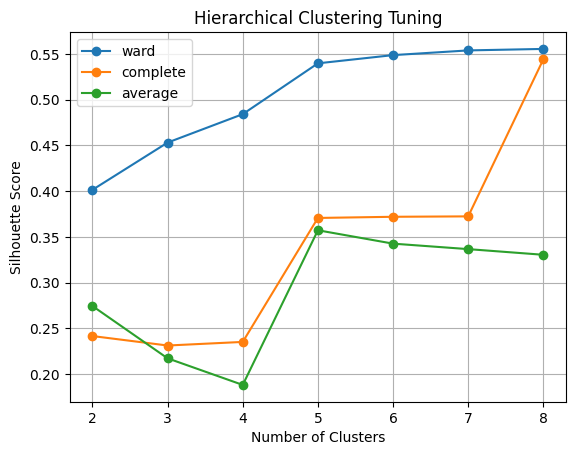

In [63]:
# Compare the linkage methods
for method in ['ward', 'complete', 'average']:

    subset = hc_results[hc_results['Linkage'] == method]

    plt.plot(
        subset['K'],
        subset['Silhouette Score'],
        marker='o',
        label=method
    )

plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Hierarchical Clustering Tuning')
plt.legend()
plt.grid(True)
plt.show()